# Roboflow labeling and YOLO26 training

## Purpose and workflow

For the soccer detection part of the challenge, we selected a roughly 30-second
clip with action from a longer video, labeled frames, and trained a YOLO26 object
detector in Roboflow. The exact frame extraction interval or selection procedure
within that clip has not been recorded. YOLO26 was a requirement for our project.
The challenge asks for assisted annotation, fine-tuning, quantitative evaluation,
and analysis of mistakes, including difficult small objects such as the ball.

We first used SAM 3 in Roboflow to generate initial player and soccer ball
annotations, then reviewed those labels ourselves. During review we used
Roboflow’s Smart Select feature to manually add missing annotations, often
adding missed soccer balls, and removed player labels from people who were
actually linemen. This human review was important
because automatically generated annotations can omit small objects and confuse
people with different roles. We did not label occluded objects. SAM analyzed frames out of order, making it
hard to follow the ball between images; the ball was also difficult to see at
the available pixel resolution. We therefore did not try to infer its position
behind players. The earlier [labeling standards](../docs/labeling-standards.md)
describe proposed guidelines and differ from this actual occlusion decision.

The earlier standards propose six team-specific player, goalkeeper, referee, and
ball classes. The Roboflow confusion matrix instead displays `ball`, `player`,
and `soccer ball`. The project class settings list `ball` (0 annotations), `player` (33,109),
and `soccer ball` (973) at the time of review. These are project-level counts,
not necessarily counts in version 5. The empty `ball` class is distinct from
`soccer ball`; the exported class IDs and the mapping to the intended schema
still need to be checked before downstream use.



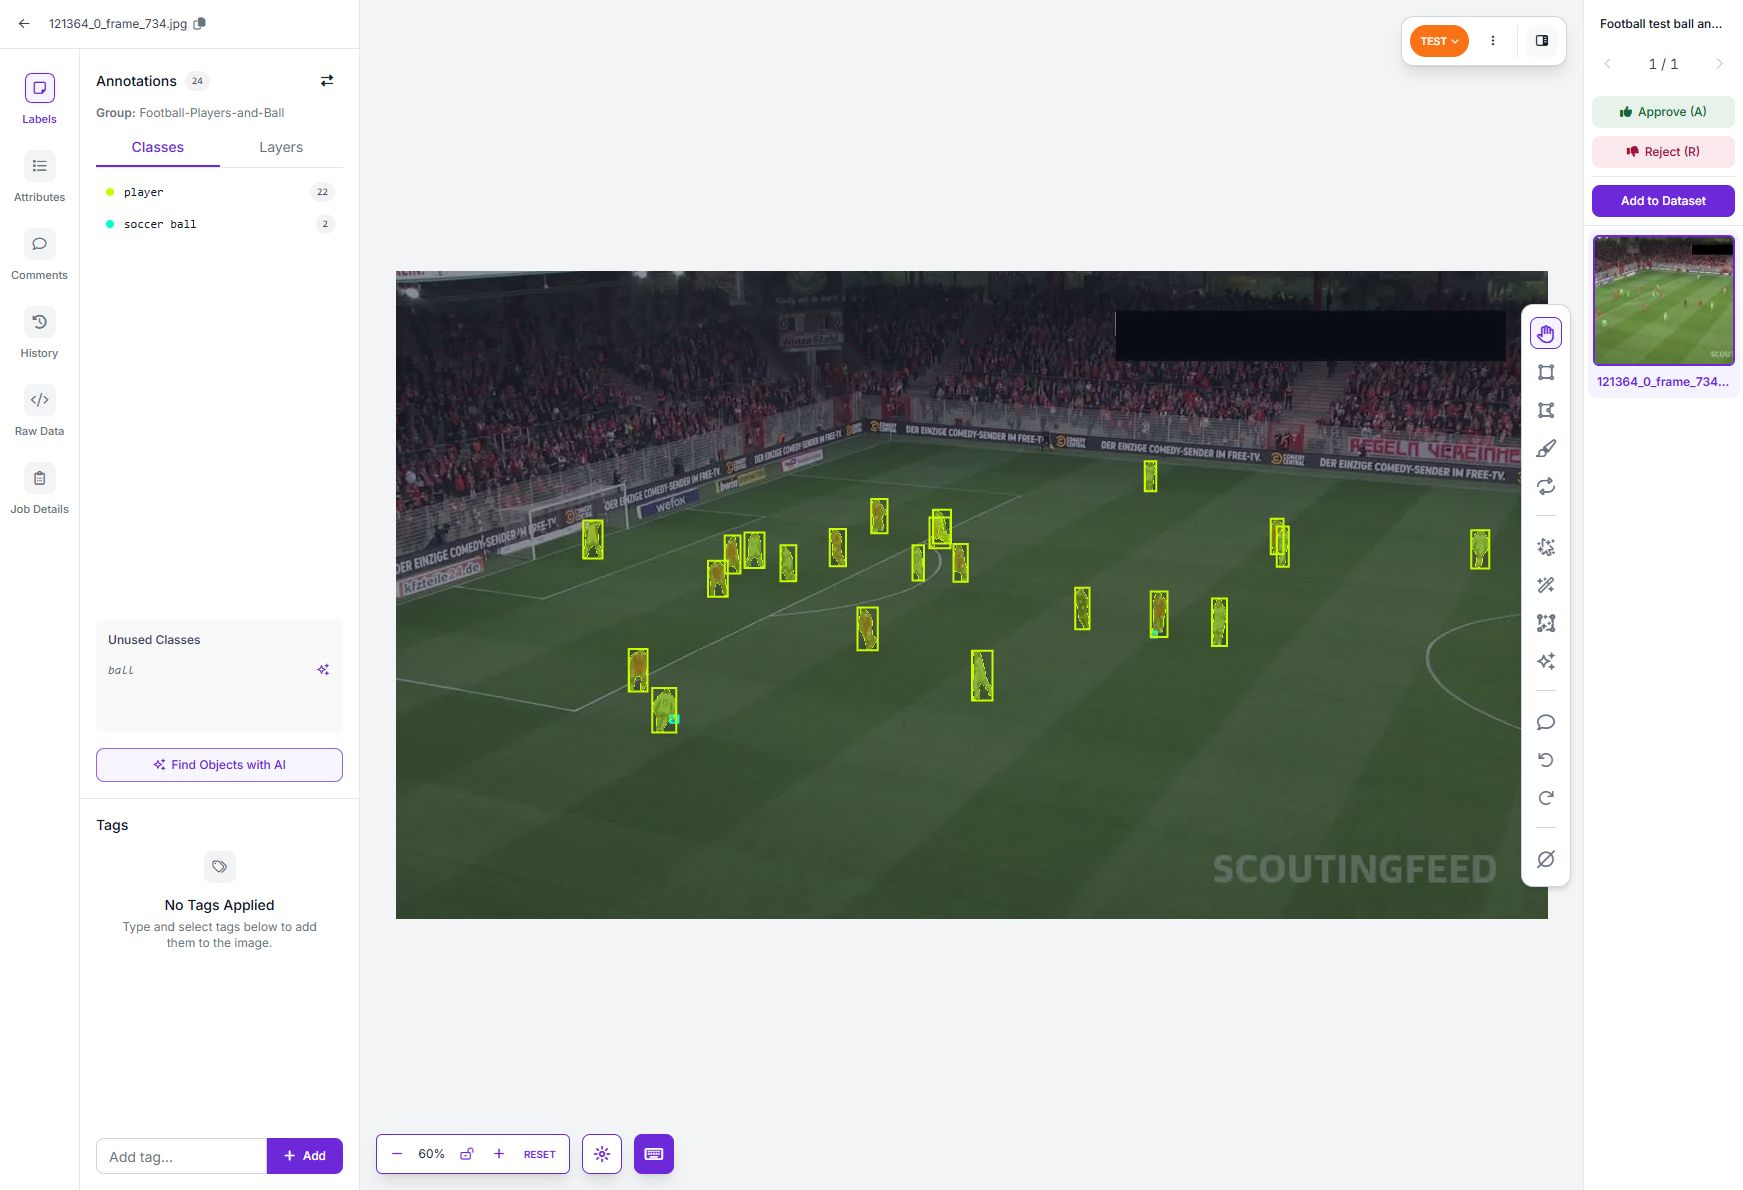

*Roboflow annotation interface showing player and soccer ball labels on a test frame. This frame is under review; its ball annotations have not been verified.*


## Dataset and preparation


The screenshots show dataset version 5 with 1,255 images after version generation:

| Split | Images | Displayed proportion |
| --- | ---: | ---: |
| Training | 1,098 | 88% |
| Validation | 104 | 8% |
| Test | 53 | 4% |

The team used the standard 70% training, 20% validation, and 10% test split
for the source images. The table shows the generated version after training
augmentation, which changes the displayed proportions; its counts should not be
confused with the original split counts. In an earlier attempt with fewer
frames, the test set had only 11 images. We considered that too few for a
reliable assessment, so we expanded the dataset across all splits to around 500
labeled frames in total. Version 5 has 53 test images.
The exact source split counts for version 5 have not been verified. The project dataset browser showed 512 images at the time of review; this is
a current project count, not necessarily the original count used in version 5.
The browser also showed adjacent frames assigned to different splits: for
example, frame 454 was validation, 455 test, and 456 training. This creates a
substantial risk of correlated footage across splits and overly optimistic
evaluation. The assignment method and whether those frames were all included
in version 5 still need verification. A new evaluation split grouped by clip or
time segment would better test generalization.

Version preprocessing applied auto-orientation and stretched images to 512 ×
512 pixels. Stretching makes inputs uniform but can change object proportions.
The version produced three outputs per training example and used these version
augmentations:

- Saturation: −25% to +25%.
- Exposure: −10% to +10%.
- Blur: up to 2.5 pixels.
- Motion blur: length 100 pixels, angle 0°, one frame.

Changes in color, exposure, and blur can expose the detector to varied visual
conditions and motion; the small ball may nevertheless be especially difficult
to recognize in blurred frames. These are motivations for the settings, not
measured effects of individual augmentations.



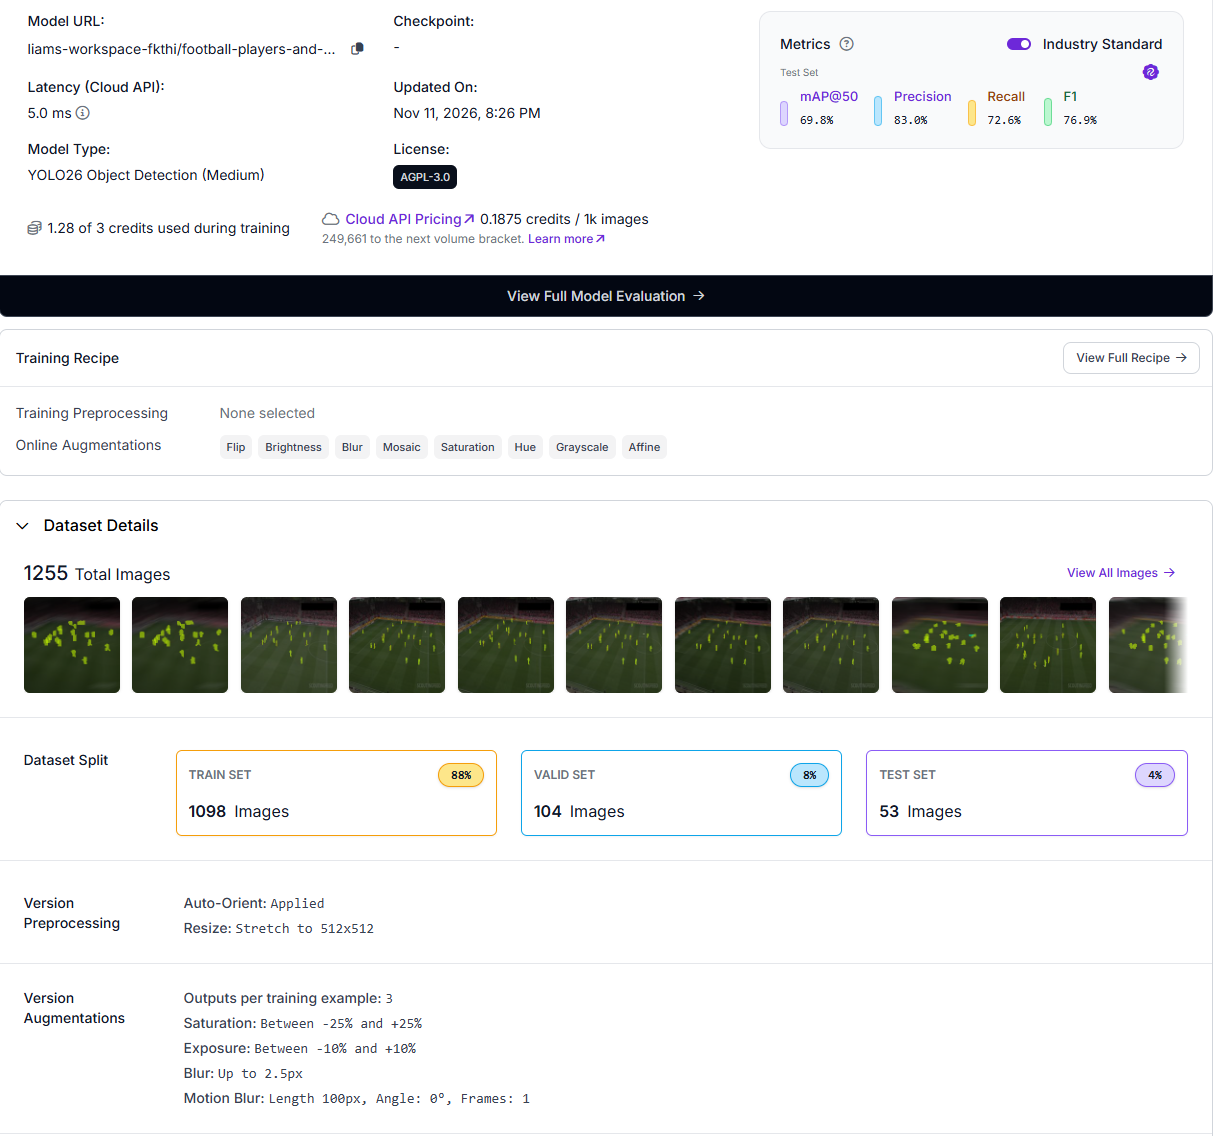

*Roboflow model overview, dataset split, preprocessing and version augmentations.*

## Label consistency and AI disclosure

The implemented Roboflow dataset uses `player` and `soccer ball` annotations; `ball` is an unused separate class. The earlier six-class proposal is not the trained model schema, and team, goalkeeper and referee identities are not represented by the two populated labels. Reviewers removed linemen incorrectly labeled as players, added missed visible balls using Smart Select, and did not infer hidden objects. These are the decisions reported by the team; detailed rules for other borderline cases should be agreed and recorded rather than assumed.

SAM 3 generated initial annotations, and the team manually reviewed and corrected them in Roboflow. Codex assisted with drafting and updating these notebooks and inspecting the Roboflow evaluation; the team should review the examples, verify the claims, and disclose this assistance according to the course policy.


Continue to [model training and evaluation](Model_training_and_evaluation.ipynb) for the training setup and results.